# Bab 9 — Text Processing and Multiclass Classification

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---

## Ringkasan Bab

Sebagian besar data di dunia nyata **tidak terstruktur** (teks, gambar, audio). Model ML hanya menerima angka, sehingga teks harus diubah menjadi vektor numerik terlebih dahulu. Bab ini membahas alur lengkap klasifikasi teks: dari teks mentah → token → vektor → model → evaluasi.

| No | Resep | Korpus (NLTK) | Inti |
|----|-------|---------------|------|
| 1 | Pengantar pemrosesan teks | `movie_reviews` (500 ulasan) | tokenisasi, stopword, `CountVectorizer` |
| 2 | Teknik vektorisasi teks | `reuters` (10.788 berita) | Bag of Words vs TF-IDF, (sekilas) word embedding |
| 3 | Ekstraksi fitur dari teks | `brown` (4 kalimat) | n-gram, POS tagging, NER |
| 4 | Implementasi model klasifikasi teks | `brown` (500 dokumen, 15 genre) | Naive Bayes, SVM, regresi logistik |
| 5 | Strategi klasifikasi multikelas | `brown` | One-vs-Rest vs One-vs-One |
| 6 | Evaluasi model teks | `movie_reviews` (2.000 ulasan) | precision, recall, F1, confusion matrix |
| 7 | Latihan | contoh kalimat kecil | TF-IDF, n-gram, klasifikasi multikelas |

> **Catatan persiapan:** notebook ini memakai korpus NLTK. Jika belum ada, jalankan sekali:
> `import nltk; [nltk.download(p) for p in ['movie_reviews','reuters','brown','punkt','punkt_tab','stopwords','averaged_perceptron_tagger_eng']]`

In [1]:
import warnings
warnings.filterwarnings('ignore')

## Resep 1 — Pengantar Pemrosesan Teks

### Teori
Langkah-langkah standar mengubah teks menjadi angka:

1. **Tokenisasi** — memecah teks menjadi unit (*token*), biasanya kata. `CountVectorizer` secara default memakai pola regex `(?u)\b\w\w+\b`: kata dengan ≥ 2 karakter alfanumerik, dan otomatis mengubah semua huruf menjadi kecil (`lowercase=True`).
2. **Penghapusan stopword** — kata yang sangat umum dan hampir tidak membawa informasi pembeda ("the", "and", "is"). `stop_words='english'` memakai daftar bawaan scikit-learn (±318 kata).
3. **Pembentukan kosakata (*vocabulary*)** — setiap token unik di data latih mendapat satu indeks kolom.
4. **Penghitungan** — dokumen $d$ direpresentasikan sebagai vektor $\mathbf{x}_d \in \mathbb{N}^{|V|}$ dengan $x_{d,t} = \text{jumlah kemunculan token } t \text{ di } d$.

Hasilnya adalah **document–term matrix** $\mathbf{X}$ berukuran $n_{\text{dokumen}} \times |V|$. Karena setiap dokumen hanya memakai sebagian kecil kosakata, hampir semua elemennya bernilai 0, sehingga disimpan sebagai **matriks sparse** (hanya elemen tak-nol yang disimpan).

Aturan *fit/transform* dari Bab 1 tetap berlaku: kosakata dibentuk **hanya dari data latih**. Kata di data uji yang tidak ada di kosakata latih (*out-of-vocabulary*) diabaikan.

### Persiapan — korpus `movie_reviews`
2.000 ulasan film (1.000 positif, 1.000 negatif). Kode buku mengambil 500 sampel secara *stratified* agar lebih cepat.

In [2]:
# Load the libraries
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import movie_reviews
import matplotlib.pyplot as plt

# Download NLTK data if not already present (specifically, the movie_reviews corpus)
try:
    movie_reviews.sents()
except LookupError:
    nltk.download('movie_reviews')

# Load the dataset from NLTK movie_reviews corpus
documents = []
labels = []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append(movie_reviews.raw(fileid))
        labels.append(category)

# Convert labels to numerical (0 for 'neg', 1 for 'pos')
label_map = {label: i for i, label in enumerate(sorted(list(set(labels))))}
numerical_labels = [label_map[label] for label in labels]


# Split the data
# Using a smaller subset for demonstration purposes to speed up processing
# and reduce memory usage, as the full movie_reviews corpus is quite large.
# You can adjust subset_size or remove this sampling for full dataset usage.
subset_size = 500 # Using 500 samples for quicker demonstration
if len(documents) > subset_size:
    # Stratified sampling to maintain class proportions
    texts_subset, _, labels_subset, _ = train_test_split(
        documents, numerical_labels, train_size=subset_size, stratify=numerical_labels, random_state=2024
    )
else:
    texts_subset = documents
    labels_subset = numerical_labels

X_train, X_test, y_train, y_test = train_test_split(texts_subset, labels_subset, test_size=0.3, random_state=2024, stratify=labels_subset)

In [3]:
# Instantiate and fit CountVectorizer() with stopword removal
vectorizer = CountVectorizer(stop_words='english')
X_train_vect = vectorizer.fit_transform(X_train)

# Transform the test data
X_test_vect = vectorizer.transform(X_test)

In [4]:
print('Jumlah dokumen latih / uji :', X_train_vect.shape[0], '/', X_test_vect.shape[0])
print('Ukuran kosakata |V|        :', X_train_vect.shape[1])
density = X_train_vect.nnz / (X_train_vect.shape[0] * X_train_vect.shape[1])
print('Proporsi elemen tak-nol    : %.2f%%  (matriks sangat sparse)' % (100 * density))
print('Rata-rata token unik / dokumen: %.0f' % (X_train_vect.nnz / X_train_vect.shape[0]))

Jumlah dokumen latih / uji : 350 / 150
Ukuran kosakata |V|        : 18881
Proporsi elemen tak-nol    : 1.36%  (matriks sangat sparse)
Rata-rata token unik / dokumen: 257


**Interpretasi.** Dari 350 ulasan latih terbentuk kosakata **18.881** kata (setelah stopword dibuang). Satu ulasan rata-rata hanya memakai ±257 kata unik, sehingga hanya **1,36%** elemen matriks yang tidak nol. Menyimpan matriks ini secara penuh (dense) akan memboroskan memori lebih dari 70×; itulah sebabnya scikit-learn mengembalikan `scipy.sparse` matrix. Perhatikan juga dimensinya: 18.881 fitur untuk 350 sampel ($p \gg n$) — situasi khas teks, dan alasan model linear (yang cocok untuk data berdimensi tinggi, lihat Bab 7) sangat populer untuk klasifikasi teks.

### Visualisasi frekuensi token

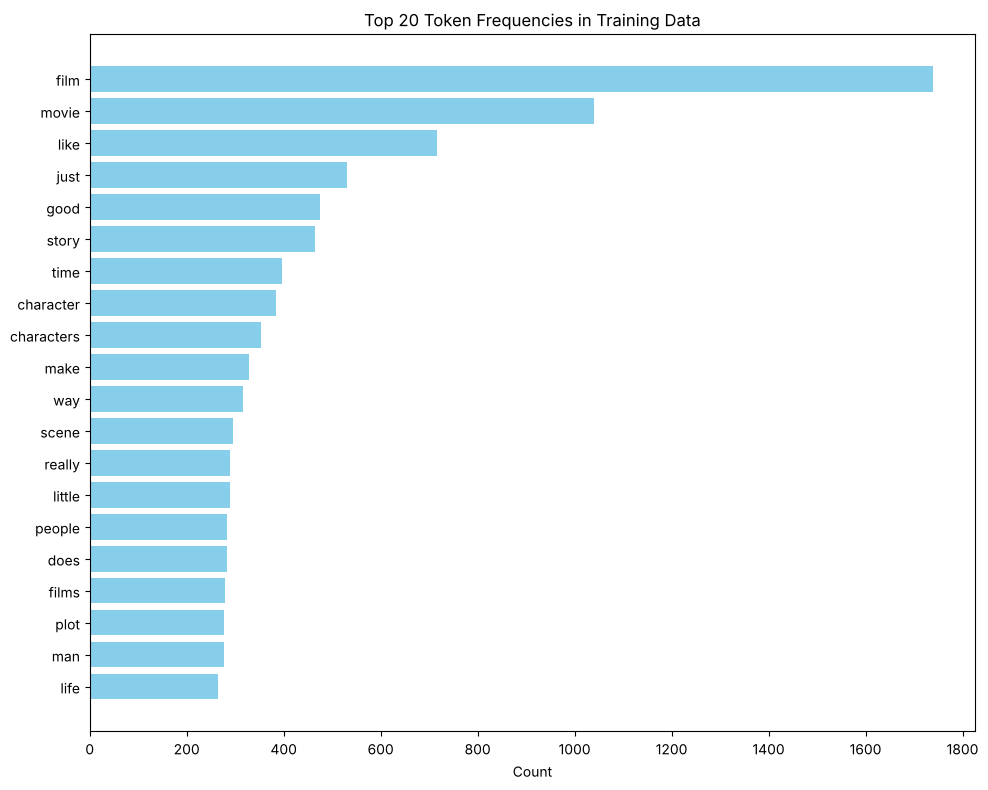

In [5]:
# Visualizing the token counts
feature_names = vectorizer.get_feature_names_out()
counts = X_train_vect.toarray().sum(axis=0)

top_n = 20 # Display top N features
num_features = len(feature_names) # Should be equal to len(counts)

if num_features > 0:
    # Sort features by count
    # argsort sorts in ascending order, [::-1] reverses it for descending
    sorted_indices = np.argsort(counts)[::-1] 
    
    actual_top_n = min(top_n, num_features)

    # Select top N features and their counts
    top_feature_names = feature_names[sorted_indices][:actual_top_n]
    top_counts = counts[sorted_indices][:actual_top_n]

    plt.figure(figsize=(10, 8)) # Adjusted figsize for better readability of N items
    plt.barh(top_feature_names, top_counts, color='skyblue')
    plt.xlabel('Count')
    plt.title(f'Top {actual_top_n} Token Frequencies in Training Data')

    # Dynamically set x-axis ticks using MaxNLocator for integer counts
    from matplotlib.ticker import MaxNLocator
    ax = plt.gca()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlim(left=0) # Ensure x-axis starts at 0

    ax.invert_yaxis() # Display the highest count at the top
    plt.tight_layout() # Adjust layout to prevent labels from overlapping
    plt.show()
else: # num_features == 0
    # Fallback for no features (e.g., if CountVectorizer found no words)
    plt.figure(figsize=(10,6)) # Use original figsize for this fallback
    plt.text(0.5, 0.5, 'No features to display.', ha='center', va='center')
    plt.title('Token Frequency in Training Data')
    plt.xticks([]) # No x-ticks
    plt.yticks([]) # No y-ticks
    plt.show()

**Interpretasi.** Token paling sering adalah **film** (±1.739 kali) dan **movie** (±1.039), disusul *like, just, good, story, time, character*. Kata-kata ini khas domain ulasan film tetapi muncul di ulasan positif **maupun** negatif, sehingga frekuensi tinggi tidak sama dengan daya pembeda tinggi. Terlihat juga keterbatasan BoW: *film/films* dan *character/characters* dihitung sebagai kata berbeda karena tidak ada *stemming/lemmatization*. Masalah "kata sering tetapi tidak informatif" inilah yang diatasi TF-IDF di resep berikutnya.

## Resep 2 — Teknik Vektorisasi Teks

### Teori

**1. Bag of Words (BoW)** — `CountVectorizer`. Dokumen dianggap "kantong kata": urutan dan tata bahasa diabaikan, hanya frekuensi yang dihitung. Kelemahan: kata yang muncul di hampir semua dokumen (misal "said" pada berita) mendapat bobot besar padahal tidak membedakan dokumen.

**2. TF-IDF** — `TfidfVectorizer`. Bobot frekuensi dikalikan dengan seberapa *langka* sebuah kata di seluruh korpus:
$$\text{tf-idf}(t,d) = \text{tf}(t,d)\times\text{idf}(t), \qquad \text{idf}(t) = \ln\frac{1+n}{1+\text{df}(t)} + 1$$
dengan $n$ = jumlah dokumen dan $\text{df}(t)$ = jumlah dokumen yang memuat kata $t$ (rumus *smooth idf* default scikit-learn; "+1" mencegah pembagian dengan nol dan agar kata yang muncul di semua dokumen tidak berbobot nol). Setelah itu setiap vektor dokumen dinormalisasi L2:
$$\mathbf{v}_d \leftarrow \frac{\mathbf{v}_d}{\lVert\mathbf{v}_d\rVert_2}$$
sehingga dokumen panjang tidak otomatis mendapat bobot lebih besar, dan perkalian titik dua vektor menjadi **cosine similarity**.

Intuisinya: kata yang **sering di satu dokumen tetapi jarang di dokumen lain** adalah kata yang paling khas untuk dokumen tersebut.

**3. Word embedding** (Word2Vec, GloVe, embedding dari model bahasa). Setiap kata dipetakan ke vektor padat berdimensi rendah (misal 100–768) yang dipelajari sedemikian rupa sehingga kata bermakna mirip berdekatan. Berbeda dengan BoW/TF-IDF yang *sparse* dan tidak paham makna (sinonim "film" dan "movie" adalah kolom berbeda), embedding menangkap semantik. scikit-learn sendiri tidak menyediakan embedding; biasanya dipakai library seperti gensim atau sentence-transformers.

### Persiapan — korpus `reuters`
10.788 artikel berita Reuters dengan 90 kategori. Label diambil dari kategori pertama setiap artikel.

In [6]:
# Load the libraries
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import reuters
import matplotlib.pyplot as plt

# Download the Reuters corpus if not already downloaded
try:
    reuters.fileids()
except LookupError:
    nltk.download('reuters')

# Load the dataset from NLTK Reuters corpus
documents = reuters.fileids()
texts = [reuters.raw(doc_id) for doc_id in documents]

labels = [reuters.categories(doc_id)[0] for doc_id in documents] # Using the first category as the label for simplicity

# Split the data
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)

In [7]:
# Bag of Words (BoW)
# Instantiate and fit CountVectorizer()
bow_vectorizer = CountVectorizer()
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

# TF-IDF Vectorization 
# Instantiate and fit TfidfVectorizer()
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

In [8]:
import pandas as pd
print('Ukuran kosakata BoW   :', X_train_bow.shape[1])
print('Ukuran kosakata TF-IDF:', X_train_tfidf.shape[1], '(kosakata sama, hanya bobotnya berbeda)')
print('Jumlah kategori label :', len(set(labels)))
print('5 kategori terbanyak  :', pd.Series(labels).value_counts().head(5).to_dict())

# Bandingkan bobot BoW vs TF-IDF untuk satu dokumen
doc = 0
vocab = bow_vectorizer.get_feature_names_out()
row_bow = X_train_bow[doc].toarray().ravel()
row_tfidf = X_train_tfidf[doc].toarray().ravel()
top_bow = np.argsort(row_bow)[::-1][:8]
display(pd.DataFrame({'kata': vocab[top_bow], 'count (BoW)': row_bow[top_bow],
                      'bobot TF-IDF': row_tfidf[top_bow].round(3),
                      'idf': tfidf_vectorizer.idf_[top_bow].round(2)}))
print('Norma L2 vektor TF-IDF dokumen ini: %.3f' % np.linalg.norm(row_tfidf))

Ukuran kosakata BoW   : 22864
Ukuran kosakata TF-IDF: 22864 (kosakata sama, hanya bobotnya berbeda)
Jumlah kategori label : 79
5 kategori terbanyak  : {'earn': 3926, 'acq': 2369, 'crude': 552, 'interest': 453, 'money-fx': 362}


,kata,count (BoW),bobot TF-IDF,idf
0,the,31,0.299,1.44
1,to,20,0.193,1.44
2,of,13,0.117,1.34
3,said,12,0.117,1.46
4,and,12,0.118,1.47
5,stock,11,0.223,3.04
6,bank,10,0.204,3.05
7,that,9,0.138,2.30


Norma L2 vektor TF-IDF dokumen ini: 1.000


**Interpretasi.**
- BoW dan TF-IDF memakai kosakata yang sama (22.864 kata); yang berbeda hanya **bobotnya**.
- Tabel di atas memperlihatkan efek IDF pada satu artikel. Kata **the** muncul 31 kali dan **to** 20 kali, tetapi idf-nya rendah (≈1,44) karena ada di hampir semua artikel. Sebaliknya **stock** (11 kali) dan **bank** (10 kali) memiliki idf ≈3,0, sehingga bobot TF-IDF-nya (≈0,22 dan ≈0,20) hampir menyamai *the* meskipun frekuensinya hanya sepertiga. Kata yang benar-benar menggambarkan isi artikel jadi lebih menonjol.
- Norma L2 vektor TF-IDF = 1, sesuai normalisasi yang dijelaskan di teori.
- Label: korpus Reuters punya 90 kategori, tetapi karena hanya kategori **pertama** yang dipakai, ada 79 label berbeda. Distribusinya sangat timpang: `earn` (3.926) dan `acq` (2.369) mencakup lebih dari separuh data.

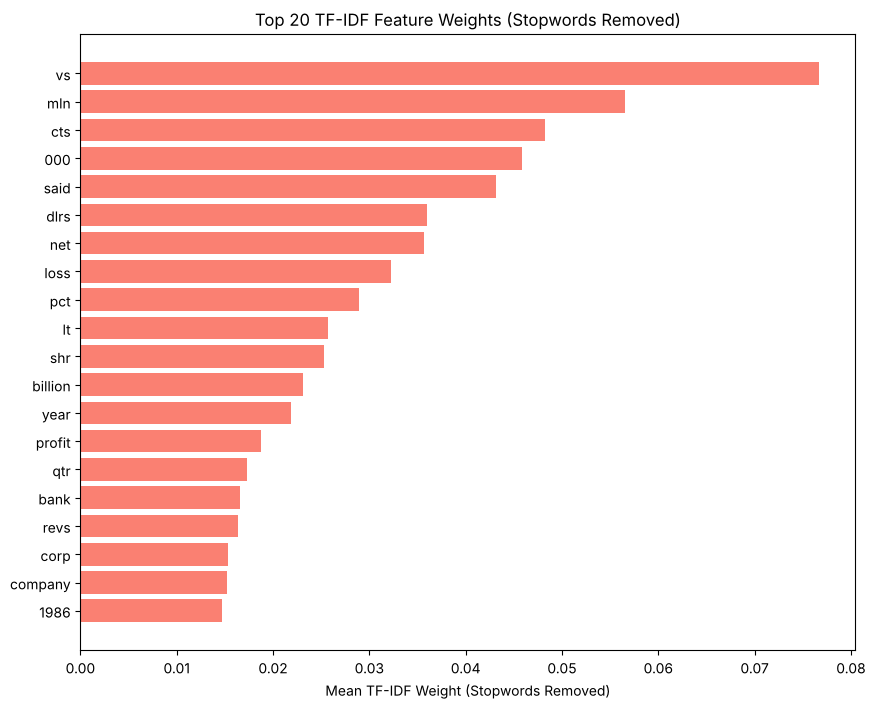

In [9]:
# Visualizing top 20 TF-IDF feature weights
# Create a TfidfVectorizer instance with English stop words removed
vis_tfidf_vectorizer = TfidfVectorizer(stop_words='english')
vis_X_train_tfidf = vis_tfidf_vectorizer.fit_transform(X_train)

# Get feature names and their mean TF-IDF weights from this new vectorization
feature_names = vis_tfidf_vectorizer.get_feature_names_out()
tfidf_means = vis_X_train_tfidf.toarray().mean(axis=0)

# Number of top terms to display
N = 20

# Ensure N is not greater than the number of available features
if len(feature_names) < N:
    N = len(feature_names)

# Get indices of the N largest TF-IDF means.
# np.argsort sorts in ascending order, so we take the last N indices.
# These indices will correspond to the N features with the highest TF-IDF scores,
# sorted from the Nth highest to the 1st highest (suitable for plt.barh to plot highest at top).
if N > 0 : # Proceed only if there are features to plot
    sorted_indices_ascending = np.argsort(tfidf_means)
    top_n_plotting_indices = sorted_indices_ascending[-N:]

    # Select the top N feature names and their TF-IDF means using these indices
    plot_feature_names = feature_names[top_n_plotting_indices]
    plot_tfidf_means = tfidf_means[top_n_plotting_indices]

    # Create the plot
    plt.figure(figsize=(10, 8)) # Adjusted figsize for better readability with 20 items
    plt.barh(plot_feature_names, plot_tfidf_means, color='salmon')
    plt.xlabel('Mean TF-IDF Weight (Stopwords Removed)')
    plt.title(f'Top {N} TF-IDF Feature Weights (Stopwords Removed)')
else: # Handle case with no features (e.g., if all features were stopwords or N=0)
    plt.figure(figsize=(10, 6)) # Original figsize for empty or minimal plot
    plt.barh([], []) # Plot empty data
    plt.xlabel('Mean TF-IDF Weight (Stopwords Removed)')
    plt.title('TF-IDF Feature Weights (No non-stopword features to display)')

plt.show()

**Interpretasi.** Kata dengan rata-rata TF-IDF tertinggi di Reuters adalah *vs, mln, cts, 000, said, dlrs, net, loss, pct, shr, profit, qtr*. Ini adalah "kosakata laporan keuangan" — singkatan khas berita pendapatan perusahaan (`mln` = million, `cts` = cents, `shr` = share, `qtr` = quarter, `dlrs` = dollars). Polanya cocok dengan fakta bahwa kategori terbesar adalah `earn` (laporan laba). Rata-rata TF-IDF memberi gambaran topik dominan sebuah korpus, tetapi bukan ukuran kata yang paling membedakan antar-kategori.

## Resep 3 — Ekstraksi Fitur dari Teks

### Teori
**N-gram** adalah urutan $n$ token berturut-turut. Kalimat "not good at all" punya unigram {not, good, at, all} dan bigram {not good, good at, at all}. Dengan unigram saja, "not good" dan "good" sulit dibedakan; bigram "not good" menangkap **konteks lokal** (termasuk negasi). `ngram_range=(1,2)` mengambil unigram sekaligus bigram. Konsekuensinya, ukuran kosakata membengkak cepat, sehingga biasanya dikombinasikan dengan `min_df`/`max_features`.

Secara probabilistik, model n-gram mengasumsikan sifat Markov: $P(w_i \mid w_1,\dots,w_{i-1}) \approx P(w_i \mid w_{i-n+1},\dots,w_{i-1})$.

**POS tagging (Part-of-Speech)** memberi label kelas kata pada setiap token — kata benda (`NN`, `NNS`, `NNP`), kata kerja (`VB`, `VBD`, `VBZ`), kata sifat (`JJ`), kata depan (`IN`), dst. menurut *Penn Treebank tagset*. NLTK memakai **averaged perceptron tagger**: classifier yang memprediksi tag tiap kata berdasarkan fitur kata itu dan tag kata-kata sebelumnya. POS tag dapat dipakai sebagai fitur tambahan (misalnya proporsi kata sifat untuk analisis sentimen).

**NER (Named Entity Recognition)** mengenali entitas bernama seperti orang, organisasi, lokasi. Buku hanya membahasnya secara konsep; implementasinya biasanya memakai `nltk.ne_chunk` atau spaCy.

### Persiapan — 4 kalimat dari korpus Brown
Kode buku sengaja memakai dataset sangat kecil (2 kalimat dari masing-masing dua kategori pertama, lalu dibagi 2 latih / 2 uji) agar output mudah dibaca.

In [10]:
# Load the libraries
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import brown
from nltk.util import ngrams as nltk_ngrams
import matplotlib.pyplot as plt
from collections import Counter 
import nltk 
from nltk.corpus import stopwords 

# Download necessary NLTK data (if not already present)
nltk.download('brown', quiet=True)
nltk.download('punkt', quiet=True)

# Load the dataset using the Brown corpus
texts = []
labels = []

# Define categories to use and number of sentences per category
# We'll use the first two categories from the Brown corpus for this example
# and take a small number of sentences from each.
# This will create a small dataset suitable for demonstration.
categories_to_use = brown.categories()[:2]  # Example: ['adventure', 'belles_lettres']
num_sents_per_category = 2  # Number of sentences to extract from each category

for i, category in enumerate(categories_to_use):
    # Get sentences for the current category
    # brown.sents() returns a list of sentences, where each sentence is a list of tokens.
    category_sents = brown.sents(categories=category)
    
    # Take the specified number of sentences from the beginning of the list
    for sent_tokens in category_sents[:num_sents_per_category]:
        texts.append(" ".join(sent_tokens))  # Join tokens to form a single string sentence
        labels.append(i)  # Assign a numerical label based on the category index

# At this point, 'texts' will contain 2*num_sents_per_category sentences,
# and 'labels' will contain corresponding integer labels (e.g., [0, 0, 1, 1] if num_sents_per_category=2)

# Split the data
# The dataset will have 4 samples if num_sents_per_category=2.
# test_size=0.5 will result in 2 training samples and 2 testing samples.
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)

In [11]:
# N-gram extraction
# Instantiate and fit CountVectorizer() with n-grams
ngram_vectorizer = CountVectorizer(ngram_range=(1,2))
X_train_ngram = ngram_vectorizer.fit_transform(X_train)
X_test_ngram = ngram_vectorizer.transform(X_test)

# Part-of-Speech (POS) Tagging using NLTK
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# POS tagging example
print("--- POS Tagging of Tokens and N-grams in Training Sentences ---")
for i, text in enumerate(X_train):
    print(f"\nOriginal Sentence {i+1}: \"{text}\"")
    tokens = nltk.word_tokenize(text)
    pos_tags = nltk.pos_tag(tokens) # This returns a list of (token, TAG) tuples

    # Display tagged unigrams (individual tokens with their tags)
    print("  Tagged Tokens (Unigrams):")
    if pos_tags: # Check if list is not empty
        # Format as: token1/TAG1 token2/TAG2 ...
        unigram_str = " ".join([f"{token}/{tag}" for token, tag in pos_tags])
        print(f"    {unigram_str}")
    else:
        print("    (No tokens to tag)")

    # Display tagged bigrams
    # A bigram here means two consecutive (token, TAG) pairs
    if len(pos_tags) >= 2:
        print("  Tagged Bigrams:")
        # nltk_ngrams on pos_tags will yield tuples like ( (token1, TAG1), (token2, TAG2) )
        tagged_bigrams = list(nltk_ngrams(pos_tags, 2))
        for bigram_tuple in tagged_bigrams:
            # bigram_tuple is, e.g., (('The', 'DT'), ('quick', 'JJ'))
            # item1 is ('The', 'DT'), item2 is ('quick', 'JJ')
            item1, item2 = bigram_tuple 
            # Format as: token1/TAG1 token2/TAG2
            bigram_display_str = f"{item1[0]}/{item1[1]} {item2[0]}/{item2[1]}"
            print(f"    {bigram_display_str}")
    else:
        print("  (Not enough tagged tokens for bigrams)")
        
print("\n--- End of POS Tagging Display ---")

--- POS Tagging of Tokens and N-grams in Training Sentences ---

Original Sentence 1: "Northern liberals are the chief supporters of civil rights and of integration ."


  Tagged Tokens (Unigrams):
    Northern/NNP liberals/NNS are/VBP the/DT chief/JJ supporters/NNS of/IN civil/JJ rights/NNS and/CC of/IN integration/NN ./.
  Tagged Bigrams:
    Northern/NNP liberals/NNS
    liberals/NNS are/VBP
    are/VBP the/DT
    the/DT chief/JJ
    chief/JJ supporters/NNS
    supporters/NNS of/IN
    of/IN civil/JJ
    civil/JJ rights/NNS
    rights/NNS and/CC
    and/CC of/IN
    of/IN integration/NN
    integration/NN ./.

Original Sentence 2: "Dan Morgan told himself he would forget Ann Turner ."
  Tagged Tokens (Unigrams):
    Dan/NNP Morgan/NNP told/VBD himself/PRP he/PRP would/MD forget/VB Ann/NNP Turner/NNP ./.
  Tagged Bigrams:
    Dan/NNP Morgan/NNP
    Morgan/NNP told/VBD
    told/VBD himself/PRP
    himself/PRP he/PRP
    he/PRP would/MD
    would/MD forget/VB
    forget/VB Ann/NNP
    Ann/NNP Turner/NNP
    Turner/NNP ./.

--- End of POS Tagging Display ---


In [12]:
print('Fitur n-gram (unigram + bigram) dari 2 kalimat latih:', len(ngram_vectorizer.get_feature_names_out()))
print(ngram_vectorizer.get_feature_names_out()[:25], '...')

Fitur n-gram (unigram + bigram) dari 2 kalimat latih: 39
['and' 'and of' 'ann' 'ann turner' 'are' 'are the' 'chief'
 'chief supporters' 'civil' 'civil rights' 'dan' 'dan morgan' 'forget'
 'forget ann' 'he' 'he would' 'himself' 'himself he' 'integration'
 'liberals' 'liberals are' 'morgan' 'morgan told' 'northern'
 'northern liberals'] ...


**Interpretasi.**
- Dua kalimat latih menghasilkan **39** fitur unigram + bigram. Bigram seperti *civil rights*, *Dan Morgan*, *Ann Turner* membawa makna yang hilang bila kata-katanya dipisah — *civil* + *rights* jauh kurang informatif daripada frasa "civil rights". Tanda baca (".") dan kata satu huruf tidak muncul karena pola token default memerlukan ≥ 2 karakter.
- **POS tagging** bekerja dengan baik: nama orang dikenali sebagai `NNP` (proper noun: *Dan, Morgan, Ann, Turner*), kata sifat sebagai `JJ` (*chief, civil*), kata kerja lampau `VBD` (*told*), modal `MD` (*would*).
- Ini juga contoh mengapa NER berguna: pola `NNP NNP` berurutan (*Dan Morgan*, *Ann Turner*) adalah petunjuk kuat adanya **entitas nama orang**.
- Dataset ini hanya 4 kalimat — sengaja untuk demonstrasi output, bukan untuk melatih model.

### Frekuensi POS tag (tanpa stopword)

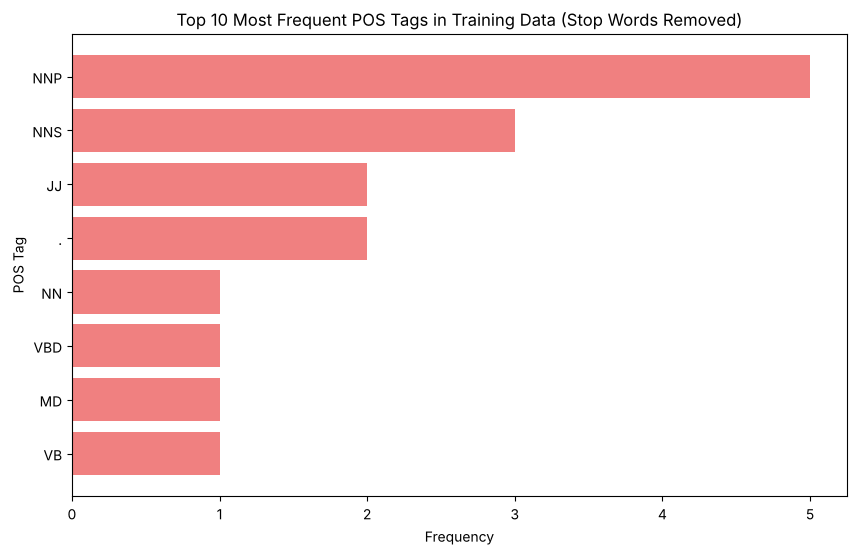

In [13]:
# Visualizing POS tag frequencies
nltk.download('stopwords', quiet=True)

# Get the set of English stop words for efficient lookup
stop_words_set = set(stopwords.words('english'))

all_individual_pos_tags = []

# Iterate through each text in X_train to extract POS tags
# X_train is assumed to be a list of strings (sentences) from previous cells.
for text_content in X_train:
    tokens = nltk.word_tokenize(text_content) # Split text into words
    
    # Filter out stop words. Comparison is case-insensitive.
    filtered_tokens = [token for token in tokens if token.lower() not in stop_words_set]

    # If the sentence becomes empty after stop word removal (e.g., all tokens were stop words),
    # or if the original sentence was empty, skip to the next sentence.
    if not filtered_tokens:
        continue
        
    # Perform Part-of-Speech tagging on the filtered tokens.
    # This returns a list of (token, TAG) tuples, e.g., [('cat', 'NN'), ('sat', 'VBD')]
    pos_tagged_tokens = nltk.pos_tag(filtered_tokens) 

    # Extract and store only the POS tags (the TAG part)
    for _, tag in pos_tagged_tokens: # We only need the tag, not the token itself for this visualization
        all_individual_pos_tags.append(tag)

# Count the frequencies of all collected individual POS tags
pos_tag_counter = Counter(all_individual_pos_tags)

# Get the 10 most common POS tags and their counts (or all if fewer than 10)
top_10_pos_tags = pos_tag_counter.most_common(10)

# Check if any POS tags were found before attempting to plot
if top_10_pos_tags:
    # Unzip the list of (tag, count) tuples into two separate lists
    tags, counts = zip(*top_10_pos_tags)

    plt.figure(figsize=(10,6)) # plt is assumed to be imported as matplotlib.pyplot
    # Create a horizontal bar chart; convert tuples from zip to lists for plotting
    plt.barh(list(tags), list(counts), color='lightcoral')
    plt.xlabel('Frequency')
    plt.ylabel('POS Tag')
    plt.title('Top 10 Most Frequent POS Tags in Training Data (Stop Words Removed)')
    plt.gca().invert_yaxis() # Invert y-axis to show the most frequent item at the top
    plt.show()
else:
    # This message is displayed if X_train was empty, all tokens were stop words,
    # or no tokens remained after filtering to be tagged.
    print("No POS tags found to display. Check X_train data and stop word filtering process.")

**Interpretasi.** Setelah stopword dibuang, tag terbanyak adalah `NNP` (5), `NNS` (3), dan `JJ` (2). Wajar, karena stopword sebagian besar adalah kata fungsi (artikel, preposisi, kata ganti), sehingga yang tersisa didominasi kata benda dan kata sifat — jenis kata yang paling banyak membawa **isi/topik**. Ini sekaligus menunjukkan mengapa penghapusan stopword biasanya tidak merugikan klasifikasi topik. Untuk analisis sentimen, kata seperti "not" (yang juga ada di daftar stopword) justru penting, sehingga stopword removal harus dipertimbangkan sesuai tugasnya.

## Resep 4 — Implementasi Model Klasifikasi Teks

### Teori

**Multinomial Naive Bayes.** Berdasarkan teorema Bayes dengan asumsi "naif" bahwa setiap kata saling independen jika kelasnya diketahui:
$$P(c\mid d) \propto P(c)\prod_{t\in d} P(t\mid c)^{x_{d,t}}, \qquad \hat P(t\mid c) = \frac{N_{c,t} + \alpha}{\sum_{t'} N_{c,t'} + \alpha|V|}$$
$N_{c,t}$ = total bobot kata $t$ di dokumen kelas $c$; $\alpha$ = *Laplace smoothing* (default 1) agar kata yang belum pernah terlihat di suatu kelas tidak membuat probabilitas menjadi nol. Prediksi memakai log agar tidak *underflow*: $\hat c = \arg\max_c [\log P(c) + \sum_t x_{d,t}\log P(t\mid c)]$. Sangat cepat (cukup menghitung frekuensi), dan bekerja baik di dimensi tinggi meski asumsinya jelas tidak benar.

**SVM** (Bab 7) — pada teks, data sangat berdimensi tinggi dan sparse sehingga kelas sering hampir terpisah linear; SVM linear adalah salah satu classifier teks klasik terbaik.

**Regresi logistik** (Bab 6) — model linear diskriminatif dengan probabilitas yang terkalibrasi lebih baik daripada Naive Bayes.

Perbedaan mendasar: Naive Bayes adalah model **generatif** (memodelkan $P(d\mid c)$), sedangkan SVM dan regresi logistik **diskriminatif** (langsung memodelkan batas/probabilitas $P(c\mid d)$). Dengan data latih sedikit, model generatif sering unggul; dengan data banyak, model diskriminatif biasanya lebih akurat (Ng & Jordan, 2002).

### Persiapan — korpus Brown lengkap
500 dokumen dari 15 genre (berita, fiksi, humor, agama, dll.), dibagi 250 latih / 250 uji secara *stratified*.

In [14]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import nltk
from nltk.corpus import brown
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report 

# Download NLTK resources (if not already downloaded)
# It's good practice to include this, though in a real notebook,
# it might be run once in a separate cell.
try:
    nltk.data.find('corpora/brown.zip')
except nltk.downloader.DownloadError:
    nltk.download('brown', quiet=True)
try:
    # Punkt is a tokenizer dependency for some NLTK corpus operations.
    nltk.data.find('tokenizers/punkt')
except nltk.downloader.DownloadError:
    nltk.download('punkt', quiet=True)

# Load the dataset from NLTK Brown corpus
document_ids = brown.fileids()
texts = [' '.join(brown.words(file_id)) for file_id in document_ids]
# Each document in Brown corpus is assigned to a category (genre).
# We use the first category as the label.
raw_labels = [brown.categories(file_id)[0] for file_id in document_ids]

# Convert string labels (categories) to numerical labels for scikit-learn
unique_raw_labels = sorted(list(set(raw_labels)))
label_to_int_mapping = {label: i for i, label in enumerate(unique_raw_labels)}
labels = [label_to_int_mapping[label] for label in raw_labels]

# Split the data
# The Brown corpus has 500 documents and 15 categories.
# The minimum number of samples per category is >20, so stratify will work fine.
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, stratify=labels, random_state=2024)

In [15]:
import pandas as pd
print('Distribusi genre (jumlah dokumen):')
print(pd.Series(raw_labels).value_counts().to_string())

Distribusi genre (jumlah dokumen):
learned            80
belles_lettres     75
lore               48
news               44
hobbies            36
government         30
fiction            29
adventure          29
romance            29
editorial          27
mystery            24
reviews            17
religion           17
humor               9
science_fiction     6


**Catatan.** Distribusi genre sangat **tidak seimbang**: `learned` punya 80 dokumen, sedangkan `science_fiction` hanya 6. Dengan pembagian 50%, beberapa genre hanya punya 3 dokumen di data latih — jauh dari cukup untuk mempelajari kelas dengan puluhan ribu fitur.

In [16]:
# Vectorize text using TF-IDF
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

# Train a Naive Bayes model
nb_clf = MultinomialNB()
nb_clf.fit(X_train_vect, y_train)

# Train an SVM model
svm_clf = SVC(random_state=2024)
svm_clf.fit(X_train_vect, y_train)

# Train a logistic regression model
lr_clf = LogisticRegression(random_state=2024, max_iter=1000)
lr_clf.fit(X_train_vect, y_train)

# Evaluate the models
models = {'Naive Bayes': nb_clf, 'SVM': svm_clf, 'Logistic Regression': lr_clf}
for name, model in models.items():
    y_pred = model.predict(X_test_vect)
    print(f'{name} Classification Report:')
    # Generate classification report as a dictionary
    # Utilize unique_raw_labels for target_names to show actual class names
    report_dict = classification_report(y_test, y_pred, target_names=unique_raw_labels, output_dict=True, zero_division=0)
    # Convert to DataFrame
    report_df = pd.DataFrame(report_dict).transpose()
    
    # Stylize the DataFrame
    styled_df = (report_df
        .style
        .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({
            'precision': '{:.3f}',
            'recall': '{:.3f}', 
            'f1-score': '{:.3f}',
            'support': '{:.0f}'
        })
    )
    display(styled_df)
    print("\n")

Naive Bayes Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,15
belles_lettres,0.173,1.000,0.295,37
editorial,0.000,0.000,0.000,14
fiction,0.000,0.000,0.000,14
government,0.000,0.000,0.000,15
hobbies,0.000,0.000,0.000,18
humor,0.000,0.000,0.000,4
learned,0.556,0.500,0.526,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12


SVM Classification Report:


,precision,recall,f1-score,support
adventure,0.400,0.133,0.200,15
belles_lettres,0.236,0.946,0.378,37
editorial,0.000,0.000,0.000,14
fiction,0.312,0.357,0.333,14
government,0.000,0.000,0.000,15
hobbies,0.000,0.000,0.000,18
humor,0.000,0.000,0.000,4
learned,0.424,0.700,0.528,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12




Logistic Regression Classification Report:


,precision,recall,f1-score,support
adventure,1.000,0.067,0.125,15
belles_lettres,0.231,0.919,0.370,37
editorial,0.000,0.000,0.000,14
fiction,0.000,0.000,0.000,14
government,0.000,0.000,0.000,15
hobbies,1.000,0.056,0.105,18
humor,0.000,0.000,0.000,4
learned,0.377,0.725,0.496,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12


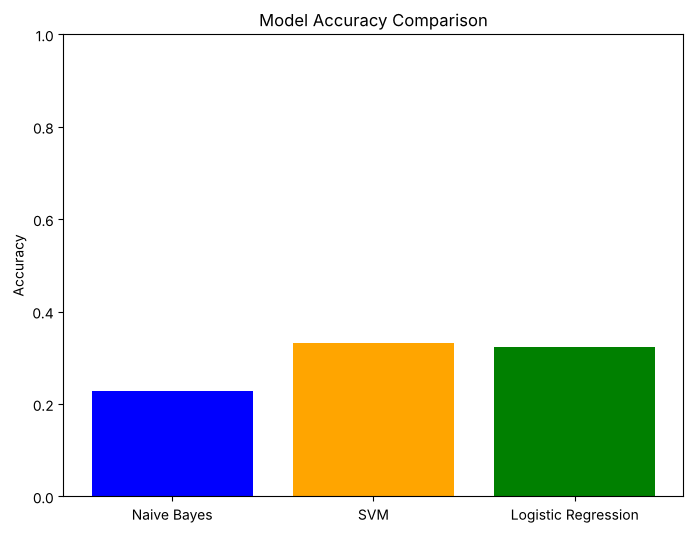

In [17]:
# Visualizing classification accuracies
model_accuracies = {}
for model_name, model_instance in models.items():
    y_pred = model_instance.predict(X_test_vect)
    # Using parameters consistent with the report generation in the preceding cells.
    # Assumes unique_raw_labels is defined and available from a previous cell,
    # as it was used in file_context_0 for generating classification reports.
    # The target_names parameter does not affect the overall 'accuracy' value but is included for consistency.
    report_dict = classification_report(y_test, y_pred, target_names=unique_raw_labels, output_dict=True, zero_division=0)
    model_accuracies[model_name] = report_dict['accuracy']

plt.figure(figsize=(8,6))

# Plotting using the calculated accuracies
# .keys() and .values() from the same dictionary will be in corresponding orders.
plt.bar(model_accuracies.keys(), model_accuracies.values(), color=['blue', 'orange', 'green'])
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1)
plt.show()

In [18]:
from sklearn.metrics import accuracy_score
for name, model in models.items():
    y_pred = model.predict(X_test_vect)
    print(f'{name:<20} akurasi = {accuracy_score(y_test, y_pred):.3f} | genre berbeda yang pernah diprediksi: {len(set(y_pred))} dari 15')
print('Baseline (selalu menebak genre terbanyak): %.3f' % (pd.Series(y_test).value_counts().max() / len(y_test)))

Naive Bayes          akurasi = 0.228 | genre berbeda yang pernah diprediksi: 2 dari 15


SVM                  akurasi = 0.332 | genre berbeda yang pernah diprediksi: 6 dari 15
Logistic Regression  akurasi = 0.324 | genre berbeda yang pernah diprediksi: 7 dari 15
Baseline (selalu menebak genre terbanyak): 0.160


**Interpretasi.** Hasilnya **buruk** untuk ketiga model, meskipun semuanya masih di atas baseline 0,160:
- **Naive Bayes: 0,228** — hanya memprediksi **2** genre (*belles_lettres* untuk 214 dokumen dan *learned* untuk sisanya). Dengan hanya 250 dokumen latih dan sangat timpang, prior $P(c)$ serta jumlah kata total kelas-kelas besar mendominasi. Kelas kecil seperti *humor* (4–5 dokumen latih) tidak pernah menang.
- **SVM (RBF, `C=1`): 0,332** dan **regresi logistik: 0,324** — sedikit lebih baik tetapi tetap hanya memprediksi 6–7 genre, dan sebagian besar prediksi jatuh ke dua genre terbesar.

Mengapa? (1) Data latih sangat sedikit per kelas (3–40 dokumen) dibandingkan ±40.000 fitur. (2) Genre Brown memang sulit dibedakan hanya dari kata (misalnya *belles_lettres* vs *learned* vs *lore* sama-sama esai nonfiksi). (3) Hyperparameter default terlalu kuat meregularisasi untuk data sekecil ini. Sel berikut menguji SVM **linear**, yang lebih cocok untuk data teks.

In [19]:
# Eksperimen tambahan: SVM LINEAR (LinearSVC) — classifier teks klasik — pada fitur yang sama
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score
lin_svm = LinearSVC().fit(X_train_vect, y_train)
p = lin_svm.predict(X_test_vect)
print('LinearSVC -> akurasi %.3f | macro-F1 %.3f | genre berbeda yang diprediksi: %d dari 15'
      % (accuracy_score(y_test, p), f1_score(y_test, p, average='macro'), len(set(p))))
for name, model in models.items():
    print(f'{name:<20} macro-F1 = {f1_score(y_test, model.predict(X_test_vect), average="macro"):.3f}')

LinearSVC -> akurasi 0.480 | macro-F1 0.376 | genre berbeda yang diprediksi: 13 dari 15
Naive Bayes          macro-F1 = 0.055


SVM                  macro-F1 = 0.160
Logistic Regression  macro-F1 = 0.146


**Interpretasi.** `LinearSVC` dengan fitur yang sama mencapai akurasi **0,48** dan macro-F1 ≈ **0,38** — jauh di atas ketiga model buku (macro-F1 Naive Bayes ≈ 0,06, SVM RBF ≈ 0,16, regresi logistik ≈ 0,15). Kernel RBF dengan `gamma='scale'` pada vektor TF-IDF yang sudah ternormalisasi menghasilkan kernel yang hampir konstan untuk semua pasangan dokumen, sehingga model sulit membedakan kelas. Pada teks berdimensi tinggi, data sudah hampir terpisah linear, jadi **kernel linear biasanya lebih tepat** — pelajaran yang sama dengan Resep 4 Bab 7.

Macro-F1 juga memperlihatkan mengapa akurasi saja menyesatkan di data timpang: akurasi Naive Bayes (0,228) terlihat "lumayan", tetapi macro-F1 ≈ 0,06 mengungkap bahwa model ini sama sekali tidak mengenali 13 dari 15 genre.

## Resep 5 — Strategi Klasifikasi Multikelas

### Teori
Banyak classifier pada dasarnya biner. Dua cara memperluasnya ke $K$ kelas:

| | One-vs-Rest (OvR) | One-vs-One (OvO) |
|---|---|---|
| Jumlah model | $K$ | $K(K-1)/2$ |
| Data tiap model | semua data (kelas $k$ vs sisanya) | hanya data dua kelas yang dibandingkan |
| Prediksi | skor/probabilitas tertinggi | voting dari semua pasangan |
| Kelemahan | tiap sub-masalah sangat tidak seimbang (1 vs $K-1$) | banyak model; tiap model hanya melihat sedikit data |

Untuk 15 genre Brown: OvR = 15 model, OvO = $15\cdot14/2 = 105$ model. OvO cocok untuk algoritma yang biayanya naik cepat dengan jumlah data (misalnya SVM kernel, kira-kira $O(n^2)$–$O(n^3)$), karena setiap model dilatih pada subset kecil. `SVC` di scikit-learn memakai OvO secara internal.

Ada juga **klasifikasi hierarkis**: pertama klasifikasikan ke kelompok besar (misal "fiksi" vs "non-fiksi"), lalu ke kelas yang lebih spesifik. Buku menyebutnya secara konsep.

### Persiapan
Teks mentah Brown (`brown.raw`, berisi token beserta tag POS-nya, misalnya `The/at Fulton/np-tl`), dibagi 350 latih / 150 uji.

In [20]:
# Load the libraries
import nltk
from nltk.corpus import brown # Changed from webtext to brown
from sklearn.model_selection import train_test_split # Ensure this is available

# Download the NLTK brown corpus if not already present
# Using quiet=True to suppress verbose download output in the notebook
try:
    _ = brown.fileids() # Check if already downloaded and accessible
except LookupError:
    nltk.download('brown', quiet=True)
except Exception: # Catch other potential NLTK setup issues
    nltk.download('brown', quiet=True)

# Load the dataset from NLTK brown corpus
file_ids = brown.fileids()
texts = [brown.raw(file_id) for file_id in file_ids]
# Use the genre of the file as its label. Each file in Brown belongs to one genre.
labels = [brown.categories(file_id)[0] for file_id in file_ids]

# Split the data
# The Brown corpus has 500 documents.
# A test_size of 0.3 will result in 350 train and 150 test samples.
# This provides significantly more samples than the previous 3 train/3 test.
# Added stratify=labels for better class distribution in splits.
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.3, random_state=2024, stratify=labels)

In [21]:
# Vectorize text using TF-IDF
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier

vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

# Implement One-vs-Rest classification
ovr_clf = OneVsRestClassifier(LogisticRegression(random_state=2024, solver='liblinear'))
ovr_clf.fit(X_train_vect, y_train)
y_pred_ovr = ovr_clf.predict(X_test_vect)

# Implement One-vs-One classification
ovo_clf = OneVsOneClassifier(LogisticRegression(random_state=2024, solver='liblinear'))
ovo_clf.fit(X_train_vect, y_train)
y_pred_ovo = ovo_clf.predict(X_test_vect)

# Evaluate the classifiers
# Added zero_division=0 to handle cases where precision/recall might be ill-defined
# due to no predicted samples or no true samples for a class.

print('One-vs-Rest Classification Report:')
report_ovr_dict = classification_report(y_test, y_pred_ovr, zero_division=0, output_dict=True)
report_ovr_df = pd.DataFrame(report_ovr_dict).transpose()
styled_ovr_df = (report_ovr_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}', 
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ovr_df)
print("\n")

print('One-vs-One Classification Report:')
report_ovo_dict = classification_report(y_test, y_pred_ovo, zero_division=0, output_dict=True)
report_ovo_df = pd.DataFrame(report_ovo_dict).transpose()
styled_ovo_df = (report_ovo_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}', 
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
display(styled_ovo_df)
print("\n")

One-vs-Rest Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,9
belles_lettres,0.224,0.773,0.347,22
editorial,0.000,0.000,0.000,8
fiction,0.000,0.000,0.000,9
government,0.000,0.000,0.000,9
hobbies,0.000,0.000,0.000,11
humor,0.000,0.000,0.000,3
learned,0.345,0.792,0.481,24
lore,0.000,0.000,0.000,14
mystery,0.000,0.000,0.000,7




One-vs-One Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,9
belles_lettres,0.185,0.773,0.298,22
editorial,0.000,0.000,0.000,8
fiction,0.000,0.000,0.000,9
government,0.000,0.000,0.000,9
hobbies,0.000,0.000,0.000,11
humor,0.000,0.000,0.000,3
learned,0.373,0.792,0.507,24
lore,0.000,0.000,0.000,14
mystery,0.000,0.000,0.000,7


In [22]:
from sklearn.metrics import accuracy_score
print('Jumlah model OvR:', len(ovr_clf.estimators_))
print('Jumlah model OvO:', len(ovo_clf.estimators_))
print('Akurasi OvR: %.3f' % accuracy_score(y_test, y_pred_ovr))
print('Akurasi OvO: %.3f' % accuracy_score(y_test, y_pred_ovo))
print('Contoh awal teks mentah:', repr(X_train[0][:120]))

Jumlah model OvR: 15
Jumlah model OvO: 105
Akurasi OvR: 0.307
Akurasi OvO: 0.273
Contoh awal teks mentah: '\n\n\tTo/to hold/vb a/at herd/nn of/in cattle/nns on/in a/at new/jj range/nn till/cs they/ppss felt/vbd at/in home/nr was/b'


**Interpretasi.**
- OvR melatih **15** model, OvO **105** model — sesuai rumus $K$ dan $K(K-1)/2$.
- Akurasi OvR 0,307 dan OvO 0,273. OvO sedikit lebih buruk di sini karena setiap model pasangan dilatih hanya dengan dokumen dari dua genre — untuk genre kecil seperti *science_fiction* (±4 dokumen latih), satu model OvO hanya melihat belasan dokumen.
- Catatan data: resep ini memakai `brown.raw()`, yang berisi kata **beserta tag POS-nya** (misalnya `To/to hold/vb a/at herd/nn`). Tokenizer default memecah `hold/vb` menjadi token `hold` dan `vb`, sehingga tag POS ikut menjadi fitur. Ini tidak salah (tag POS bisa membantu membedakan gaya tulisan antar-genre), tetapi berbeda dari Resep 4 yang memakai `brown.words()` (hanya kata).

## Resep 6 — Evaluasi Model Teks

### Teori
Metrik dasarnya sama dengan Bab 4 dan 6 (precision, recall, F1, confusion matrix). Untuk multikelas atau ketika melaporkan satu angka, ada tiga cara merata-ratakan:
- **macro** — rata-rata biasa antar kelas; setiap kelas dianggap sama penting (kelas kecil berpengaruh besar).
- **weighted** — rata-rata yang dibobot *support* (jumlah sampel) tiap kelas.
- **micro** — hitung TP/FP/FN total semua kelas lalu hitung metriknya; untuk klasifikasi single-label, micro-F1 = akurasi.

Pada data seimbang (seperti `movie_reviews`, 50:50) ketiganya hampir sama. Pada data tidak seimbang (seperti genre Brown), macro-F1 jauh lebih jujur karena tidak "tertutupi" kelas besar.

Untuk evaluasi teks generatif (misalnya keluaran LLM) diperlukan metrik lain seperti BLEU, ROUGE, atau penilaian manusia — di luar cakupan buku.

### Persiapan — `movie_reviews` lengkap (2.000 ulasan), dibagi 1.000 / 1.000

In [23]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import movie_reviews
import random

# Download NLTK data (movie_reviews corpus) if not already downloaded
try:
    # Check if the corpus is accessible
    movie_reviews.categories()
except LookupError:
    nltk.download('movie_reviews')

# Load the dataset from NLTK movie_reviews corpus
documents = []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append((list(movie_reviews.words(fileid)), category))

# Shuffle the documents for better splitting.
# Using a fixed seed for reproducibility, consistent with random_state in train_test_split.
random.seed(2024)
random.shuffle(documents)

# Prepare texts (joining words into strings) and labels
texts = [" ".join(words) for words, category in documents]
labels = [category for words, category in documents]

# Split the data
# Kept test_size and random_state as in the original selection
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)

Precision: 0.8034174884733607
Recall: 0.803
F1 Score: 0.8029765558512367

Classification Report:


,precision,recall,f1-score,support
neg,0.791016,0.818182,0.804369,495.000000
pos,0.815574,0.788119,0.801611,505.000000
accuracy,0.803000,0.803000,0.803000,0.803000
macro avg,0.803295,0.803150,0.802990,1000.000000
weighted avg,0.803417,0.803000,0.802977,1000.000000


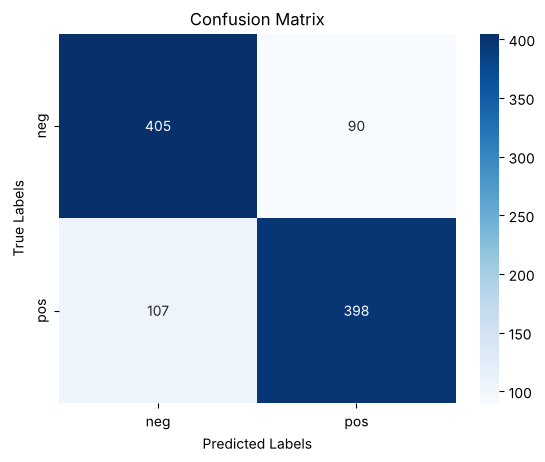

In [24]:
# Vectorize text using TF-IDF
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

# Train a logistic regression classifier
clf = LogisticRegression(random_state=2024)
clf.fit(X_train_vect, y_train)

# Make predictions
y_pred = clf.predict(X_test_vect)

# Evaluate the model
print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))

# Generate classification report as a styled DataFrame
report_dict = classification_report(y_test, y_pred, labels=clf.classes_, target_names=clf.classes_, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).transpose()

print("\nClassification Report:")
display(report_df.style.set_caption("Classification Report"))

# Generate and visualize a confusion matrix
# The confusion_matrix function computes class-wise accuracy.
# labels=clf.classes_ ensures the matrix rows/columns follow a consistent order.
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=clf.classes_, yticklabels=clf.classes_, cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [25]:
coef = clf.coef_[0]
vocab = vectorizer.get_feature_names_out()
order = np.argsort(coef)
print('Kelas positif model =', clf.classes_[1])
print('\n15 kata paling "negatif":', list(vocab[order[:15]]))
print('\n15 kata paling "positif":', list(vocab[order[-15:][::-1]]))

Kelas positif model = pos

15 kata paling "negatif": ['bad', 'movie', 'this', 'plot', 'boring', 'worst', 'there', 'have', 'no', 'stupid', 'supposed', 'nothing', 'only', 'any', 'why']

15 kata paling "positif": ['and', 'is', 'as', 'his', 'life', 'war', 'mulan', 'great', 'truman', 'very', 'of', 'men', 'true', 'many', 'jackie']


**Interpretasi.**
- Precision, recall, dan F1 (weighted) semuanya ≈ **0,80**. Karena kedua kelas hampir seimbang di data uji, rata-rata *weighted* dan *macro* praktis sama.
- Confusion matrix: dari 1.000 ulasan uji, 405 negatif dan 398 positif diklasifikasikan benar; 90 ulasan negatif salah dianggap positif dan 107 ulasan positif salah dianggap negatif. Kesalahannya cukup seimbang di kedua arah.
- **Koefisien model** memperlihatkan apa yang dipelajari: kata paling negatif adalah *bad, boring, worst, stupid, nothing, supposed* — sangat masuk akal. Kata *supposed* ("was supposed to be funny…") dan *why* adalah sinyal kekecewaan yang tidak terduga. Di sisi positif muncul *great, true, life*, tetapi juga nama seperti *mulan, truman, jackie* — film tertentu yang kebetulan mendapat beberapa ulasan positif. Ini tanda model menghafal nama yang tidak akan berguna untuk film lain (overfitting ringan terhadap kosakata data latih).
- Kata *movie* termasuk sinyal negatif dan kata fungsi *and, is, of* termasuk sinyal positif; ulasan positif cenderung lebih panjang dan deskriptif, ulasan negatif lebih sering menyebut "this movie".

In [26]:
# Eksperimen tambahan: bigram + sublinear TF + LinearSVC pada data yang sama
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
for ngram in [(1, 1), (1, 2)]:
    vec = TfidfVectorizer(ngram_range=ngram, min_df=2, sublinear_tf=True)
    A, B = vec.fit_transform(X_train), vec.transform(X_test)
    acc = accuracy_score(y_test, LinearSVC().fit(A, y_train).predict(B))
    print(f'ngram_range={ngram} | jumlah fitur={A.shape[1]:>6} | akurasi LinearSVC={acc:.3f}')

ngram_range=(1, 1) | jumlah fitur= 17018 | akurasi LinearSVC=0.867


ngram_range=(1, 2) | jumlah fitur= 76974 | akurasi LinearSVC=0.873


**Interpretasi.** Hanya dengan mengganti model menjadi `LinearSVC` serta memakai `sublinear_tf=True` (memakai $1+\log(\text{tf})$ agar kata yang diulang-ulang tidak terlalu dominan) dan `min_df=2` (membuang kata yang hanya muncul di satu dokumen — biasanya nama atau salah ketik), akurasi naik dari 0,80 menjadi ≈ **0,87**. Menambah bigram memberi tambahan kecil (≈0,873), misalnya karena frasa seperti "not good" kini menjadi fitur tersendiri. Pilihan representasi teks sering sama pentingnya dengan pilihan algoritma.

## Latihan Praktik

### Latihan 1 — Preprocessing dan vektorisasi teks

In [27]:
# Load libraries
from sklearn.feature_extraction.text import TfidfVectorizer

# Load the Dataset
texts = [
    "Data preprocessing is essential.",
    "Vectorization transforms text.",
    "Clean data improves model performance.",
    "Machine learning algorithms use numerical data."
]

# Preprocess the Data (basic cleaning)
texts_cleaned = [text.lower() for text in texts]

# Vectorize the Text
vectorizer = TfidfVectorizer()
vectorizer.fit_transform(texts_cleaned)

# Print the vectorized features
vectorizer.get_feature_names_out()

array(['algorithms', 'clean', 'data', 'essential', 'improves', 'is',
       'learning', 'machine', 'model', 'numerical', 'performance',
       'preprocessing', 'text', 'transforms', 'use', 'vectorization'],
      dtype=object)

**Interpretasi.** Empat kalimat pendek menghasilkan kosakata **16** kata. Kosakata diurutkan alfabetis, dan tanda titik hilang karena tokenizer hanya mengambil kata. Langkah `lower()` di sini sebenarnya tidak wajib karena `TfidfVectorizer` sudah otomatis mengubah huruf menjadi kecil — tetapi preprocessing manual berguna untuk pembersihan lain (menghapus URL, angka, tag HTML, dll.).

### Latihan 2 — Ekstraksi fitur n-gram

In [28]:
# Load libraries
from sklearn.feature_extraction.text import CountVectorizer

# Load the Dataset
texts = [
    "Feature extraction is crucial.",
    "N-grams capture context.",
    "Models benefit from good features.",
    "Contextual information enhances classification."
]

# Extract N-gram Features
ngram_vectorizer = CountVectorizer(ngram_range=(1,2))
ngram_vectorizer.fit_transform(texts)

# Print the extracted n-gram features
ngram_vectorizer.get_feature_names_out()

array(['benefit', 'benefit from', 'capture', 'capture context',
       'classification', 'context', 'contextual',
       'contextual information', 'crucial', 'enhances',
       'enhances classification', 'extraction', 'extraction is',
       'feature', 'feature extraction', 'features', 'from', 'from good',
       'good', 'good features', 'grams', 'grams capture', 'information',
       'information enhances', 'is', 'is crucial', 'models',
       'models benefit'], dtype=object)

**Interpretasi.** Dengan `ngram_range=(1,2)`, empat kalimat menghasilkan 28 fitur: unigram ditambah bigram seperti *feature extraction*, *capture context*, *good features*. Perhatikan kata "N-grams" dipecah menjadi `grams` karena huruf tunggal "N" tidak memenuhi pola token minimal 2 karakter — contoh kecil bagaimana pola tokenisasi default bisa mengubah teks secara tak terduga.

### Latihan 3 — Membangun dan mengevaluasi classifier multikelas

In [29]:
# Load libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Load the Dataset
texts = [
    "This is an economic news article.",
    "Sports events are exciting.",
    "Technology advances rapidly.",
    "Politics affect global relations."
]
labels = ["Economy", "Sports", "Technology", "Politics"]

# Vectorize Text
vectorizer = TfidfVectorizer()
X_vect = vectorizer.fit_transform(texts)

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X_vect, labels, test_size=0.5, random_state=2024)

# Train the Classifier
clf = LogisticRegression(random_state=2024)
clf.fit(X_train, y_train)

# Make Predictions and Evaluate
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

     Economy       0.00      0.00      0.00       0.0
    Politics       0.00      0.00      0.00       1.0
      Sports       0.00      0.00      0.00       1.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0



In [30]:
print('Label latih:', y_train)
print('Label uji  :', y_test)
print('Prediksi   :', list(y_pred))

Label latih: ['Technology', 'Economy']
Label uji  : ['Sports', 'Politics']
Prediksi   : [np.str_('Economy'), np.str_('Economy')]


**Interpretasi.** Akurasi **0** — dan ini sudah bisa diduga dari desain datanya. Setiap kalimat punya label berbeda, sehingga setelah dibagi 2 latih / 2 uji, model hanya belajar label *Technology* dan *Economy*, sedangkan data uji berlabel *Sports* dan *Politics* — dua kelas yang **tidak pernah dilihat** saat pelatihan. Sebuah classifier tidak mungkin memprediksi kelas yang tidak ada di data latihnya; model akhirnya menebak *Economy* untuk keduanya.

Latihan ini hanya mendemonstrasikan alur kode (vektorisasi → split → latih → evaluasi). Untuk masalah nyata dibutuhkan banyak contoh per kelas, dan `train_test_split(..., stratify=labels)` agar setiap kelas muncul di data latih maupun uji.

## Kesimpulan Bab 9

- Teks harus diubah menjadi vektor numerik: **tokenisasi → (stopword) → kosakata → vektor**. Hasilnya matriks berdimensi sangat tinggi dan sangat sparse.
- **BoW** menghitung frekuensi; **TF-IDF** menurunkan bobot kata yang umum di banyak dokumen dan menormalkan panjang dokumen; **word embedding** menangkap makna.
- **N-gram** menambah konteks lokal (termasuk negasi); **POS tagging** dan **NER** menambah informasi linguistik.
- **Naive Bayes** (generatif, cepat), **SVM** linear dan **regresi logistik** (diskriminatif) adalah baseline kuat untuk klasifikasi teks — tetapi butuh cukup data per kelas.
- Multikelas: **OvR** ($K$ model) vs **OvO** ($K(K-1)/2$ model).
- Evaluasi dengan precision/recall/F1 dan confusion matrix; pada kelas tidak seimbang gunakan **macro-F1** dan bandingkan dengan baseline kelas mayoritas.